# 🫀 ACDC — Data preprocessing (2D, slice by slice)

Ce notebook prépare les volumes ACDC pour l'entraînement d'un modèle de segmentation.
Il **ne fait pas** d'augmentation de données ni d'entraînement : ces étapes viendront dans des notebooks séparés.

**Structure attendue sur Google Drive :**
```
MyDrive/segmentation_cardiaque/
├── train/patientXXX/   (Info.cfg, *_frameYY.nii.gz, *_frameYY_gt.nii.gz, ...)
├── test/patientXXX/
└── preprocessed/       (créé par ce notebook)
```

**Ce que fait le notebook :**
1. Rééchantillonne chaque coupe dans le plan à un **spacing commun** (1.5 mm), pour que tous les patients aient la même échelle physique.
2. Normalise l'intensité de chaque volume (écrêtage aux percentiles 0.5 / 99.5, puis z-score).
3. Centre et recadre/complète chaque coupe à une taille fixe (256 × 256). **Ce cadrage n'utilise pas le masque**, pour rester valable sur les images sans annotation (test réel).
4. Ne traite que les frames **ED** et **ES** (les seules annotées).
5. Sauvegarde chaque volume en `.npz`, avec un fichier `.json` de métadonnées (décalages nécessaires pour revenir à la grille d'origine).
6. Crée une séparation **train / validation par patient**, stratifiée par groupe clinique.

> ⚠️ L'épaisseur entre coupes (5–10 mm) n'est **pas** rééchantillonnée : on reste en 2D coupe par coupe. Les coupes sans cœur sont conservées ici et filtrées au moment du chargement.

**Exécution :** lancez les cellules dans l'ordre. Le traitement est reprenable : si la session Colab s'arrête, relancez simplement la cellule de traitement (les fichiers déjà produits sont ignorés).

## 1. Mounting Google Drive and installation

In [2]:
%pip install -q nibabel scikit-learn tqdm
import os
from google.colab import drive

if not os.path.ismount("/content/drive/MyDrive"):
    drive.mount("/content/drive", force_remount=True)

print("Drive monté :", os.path.exists("/content/drive/MyDrive/segmentation_cardiaque"))

Mounted at /content/drive
Drive monté : True


## 2. Imports and configuration

In [3]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

DATA_ROOT = Path("/content/drive/MyDrive/segmentation_cardiaque")
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"
OUT_DIR = DATA_ROOT / "preprocessed"

TARGET_SPACING = 1.5
TARGET_SIZE = 256
CLIP_PERCENTILES = (0.5, 99.5)
VAL_SIZE = 0.2
SEED = 42
OVERWRITE = False

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dossier introuvable : {DATA_ROOT}")
for d in (TRAIN_DIR, TEST_DIR):
    print(d.name, "→", "OK" if d.exists() else "INTROUVABLE", f"({len(list(d.glob('patient*')))} patients)")
OUT_DIR.mkdir(parents=True, exist_ok=True)

train → OK (100 patients)
test → OK (50 patients)


## 3. Utility functions

In [4]:
def read_cfg(path):
    cfg = {}
    for line in Path(path).read_text().splitlines():
        if ":" in line:
            key, value = line.split(":", 1)
            cfg[key.strip()] = value.strip()
    return cfg


def list_patients(split_dir):
    """Renvoie la liste des patients (avec ED, ES et groupe clinique) d'un dossier split."""
    rows = []
    for pdir in sorted(split_dir.glob("patient*")):
        cfg_path = pdir / "Info.cfg"
        if not pdir.is_dir() or not cfg_path.exists():
            continue
        cfg = read_cfg(cfg_path)
        rows.append(dict(patient=pdir.name, dir=pdir, group=cfg.get("Group"),
                         ED=int(cfg["ED"]), ES=int(cfg["ES"])))
    return rows


def frame_paths(pdir, pid, frame):
    img = pdir / f"{pid}_frame{frame:02d}.nii.gz"
    gt = pdir / f"{pid}_frame{frame:02d}_gt.nii.gz"
    return img, (gt if gt.exists() else None)


def resample_inplane(vol, spacing_xy, order):
    """Rééchantillonne (x, y) au TARGET_SPACING ; la dimension Z est conservée."""
    factors = (spacing_xy[0] / TARGET_SPACING, spacing_xy[1] / TARGET_SPACING, 1.0)
    return ndimage.zoom(vol, factors, order=order)


def normalize(img):
    lo, hi = np.percentile(img, CLIP_PERCENTILES)
    img = np.clip(img, lo, hi)
    return (img - img.mean()) / (img.std() + 1e-8)


def fit_axis(vol, axis, size, pad_value):
    """Centre-recadre ou complète un axe à `size`. Renvoie le volume et le décalage (positif = rogné au début, négatif = complété au début)."""
    n = vol.shape[axis]
    if n > size:
        start = (n - size) // 2
        return np.take(vol, np.arange(start, start + size), axis=axis), start
    if n < size:
        before = (size - n) // 2
        after = size - n - before
        width = [(0, 0)] * vol.ndim
        width[axis] = (before, after)
        return np.pad(vol, width, mode="constant", constant_values=pad_value), -before
    return vol, 0


def fit_volume(vol, pad_value):
    vol, sx = fit_axis(vol, 0, TARGET_SIZE, pad_value)
    vol, sy = fit_axis(vol, 1, TARGET_SIZE, pad_value)
    return vol, (sx, sy)


def preprocess_frame(img_path, gt_path=None):
    """Pipeline complet pour une frame 3D. Renvoie (image, masque ou None, métadonnées)."""
    img_nii = nib.load(str(img_path))
    spacing_xy = img_nii.header.get_zooms()[:2]
    img = np.asanyarray(img_nii.dataobj).astype(np.float32)

    img_r = normalize(resample_inplane(img, spacing_xy, order=1))
    img_f, shifts = fit_volume(img_r, pad_value=float(img_r.min()))

    info = dict(
        orig_shape=list(img.shape),
        spacing_xy=[round(float(s), 3) for s in spacing_xy],
        resampled_shape=list(img_r.shape),
        shift_x=int(shifts[0]), shift_y=int(shifts[1]),
        n_slices=int(img_f.shape[2]),
    )

    mask_f = None
    if gt_path is not None:
        gt = np.asanyarray(nib.load(str(gt_path)).dataobj).astype(np.uint8)
        gt_r = resample_inplane(gt, spacing_xy, order=0)
        mask_f, _ = fit_volume(gt_r, pad_value=0)
        before, after = int((gt_r > 0).sum()), int((mask_f > 0).sum())
        info.update(
            fg_vox_before_crop=before,
            fg_vox_lost=before - after,
            slices_with_heart=int((mask_f > 0).any(axis=(0, 1)).sum()),
            class_vox={str(c): int((mask_f == c).sum()) for c in range(4)},
        )
    return img_f.astype(np.float16), (None if mask_f is None else mask_f.astype(np.uint8)), info

## 4. Test on one patient
Vérifions d'abord le pipeline sur un seul patient avant de lancer le traitement complet.

In [5]:
demo = list_patients(TRAIN_DIR)[0]
img_p, gt_p = frame_paths(demo["dir"], demo["patient"], demo["ED"])
img_f, mask_f, info = preprocess_frame(img_p, gt_p)
print(demo["patient"], "ED → image", img_f.shape, img_f.dtype, "| masque", mask_f.shape, mask_f.dtype)
print(json.dumps(info, indent=2))

patient001 ED → image (256, 256, 10) float16 | masque (256, 256, 10) uint8
{
  "orig_shape": [
    216,
    256,
    10
  ],
  "spacing_xy": [
    1.562,
    1.562
  ],
  "resampled_shape": [
    225,
    267,
    10
  ],
  "shift_x": -15,
  "shift_y": 5,
  "n_slices": 10,
  "fg_vox_before_crop": 26682,
  "fg_vox_lost": 0,
  "slices_with_heart": 9,
  "class_vox": {
    "0": 628678,
    "1": 6192,
    "2": 7431,
    "3": 13059
  }
}


## 5. Processing all volumes (train and test)

Chaque frame ED/ES est sauvegardée dans `preprocessed/<split>/<patient>_<phase>.npz`, avec un `.json` de métadonnées à côté.

In [6]:
def process_split(split_name, split_dir):
    out = OUT_DIR / split_name
    out.mkdir(parents=True, exist_ok=True)
    rows = []
    for p in tqdm(list_patients(split_dir), desc=split_name):
        for phase in ("ED", "ES"):
            frame = p[phase]
            stem = f"{p['patient']}_{phase}"
            npz_path, json_path = out / f"{stem}.npz", out / f"{stem}.json"

            if npz_path.exists() and json_path.exists() and not OVERWRITE:
                info = json.loads(json_path.read_text())
            else:
                img_p, gt_p = frame_paths(p["dir"], p["patient"], frame)
                img_f, mask_f, info = preprocess_frame(img_p, gt_p)
                arrays = {"image": img_f}
                if mask_f is not None:
                    arrays["mask"] = mask_f
                np.savez_compressed(npz_path, **arrays)
                json_path.write_text(json.dumps(info))

            rows.append(dict(split=split_name, patient=p["patient"], group=p["group"], phase=phase,
                             frame=frame, npz=str(npz_path.relative_to(DATA_ROOT)), **info))
    return rows

rows = process_split("train", TRAIN_DIR) + process_split("test", TEST_DIR)
meta = pd.DataFrame(rows)
print(f"{len(meta)} volumes traités")

train:   0%|          | 0/100 [00:00<?, ?it/s]

test:   0%|          | 0/50 [00:00<?, ?it/s]

300 volumes traités


## 6. Patient-level train / validation split

On découpe au niveau **patient** (et non coupe) pour éviter toute fuite entre les deux ensembles, en stratifiant par groupe clinique.

In [7]:
train_patients = meta[meta["split"] == "train"].drop_duplicates("patient")[["patient", "group"]]
_, val_ids = train_test_split(
    train_patients["patient"], test_size=VAL_SIZE,
    stratify=train_patients["group"], random_state=SEED,
)
val_ids = set(val_ids)

meta["subset"] = np.where(meta["split"] == "test", "test",
                          np.where(meta["patient"].isin(val_ids), "val", "train"))

meta.to_csv(OUT_DIR / "metadata.csv", index=False)
print(meta.groupby(["subset", "group"])["patient"].nunique().unstack(fill_value=0))
print("\nMétadonnées sauvegardées dans :", OUT_DIR / "metadata.csv")

group   DCM  HCM  MINF  NOR  RV
subset                         
test     10   10    10   10  10
train    16   16    16   16  16
val       4    4     4    4   4

Métadonnées sauvegardées dans : /content/drive/MyDrive/segmentation_cardiaque/preprocessed/metadata.csv


## 7. Quality checks
- **Fond perdu lors du recadrage** : nombre de voxels de cœur qui sortent de la fenêtre 256 × 256. Doit rester très faible.
- **Coupes sans cœur** : proportion attendue autour de 5 %, d'après l'exploration.

In [8]:
qc = meta[meta["split"] == "train"].copy()
qc["lost_pct"] = 100 * qc["fg_vox_lost"] / qc["fg_vox_before_crop"].clip(lower=1)

print("Pourcentage de voxels de cœur perdus au recadrage :")
print(qc["lost_pct"].describe().round(3).to_string())

print("\nVolumes avec plus de 0.5 % de cœur perdu :")
print(qc[qc["lost_pct"] > 0.5][["patient", "phase", "orig_shape", "spacing_xy", "lost_pct"]].to_string(index=False)
      or "aucun")

empty = meta["n_slices"].sum() - meta["slices_with_heart"].sum()
print(f"\nCoupes sans cœur : {empty} / {meta['n_slices'].sum()} ({100 * empty / meta['n_slices'].sum():.1f} %)")

Pourcentage de voxels de cœur perdus au recadrage :
count    200.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0

Volumes avec plus de 0.5 % de cœur perdu :
Empty DataFrame
Columns: [patient, phase, orig_shape, spacing_xy, lost_pct]
Index: []

Coupes sans cœur : 136 / 2978 (4.6 %)


## 8. Visual check
Quelques coupes prétraitées avec leur masque, pour vérifier visuellement l'alignement après recadrage.

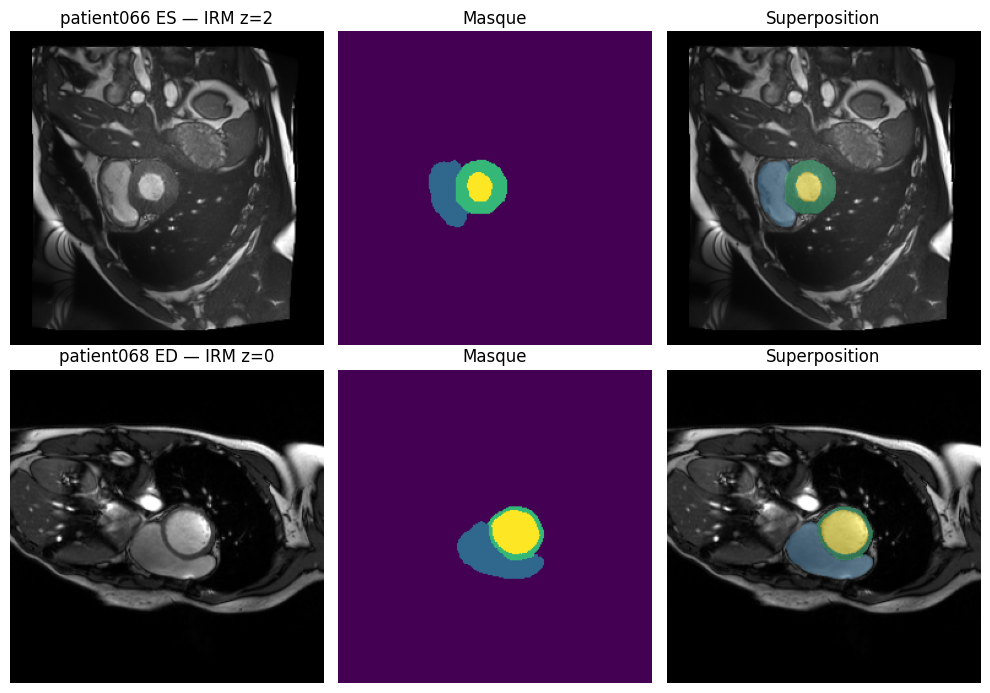

In [9]:
sample = meta[(meta["subset"] == "train")].sample(2, random_state=SEED)
fig, axes = plt.subplots(len(sample), 3, figsize=(10, 3.5 * len(sample)))
axes = np.atleast_2d(axes)

for row_ax, (_, r) in zip(axes, sample.iterrows()):
    data = np.load(DATA_ROOT / r["npz"])
    img, mask = data["image"].astype(np.float32), data["mask"]
    z = int(np.argmax((mask > 0).sum(axis=(0, 1))))
    im = np.rot90(img[:, :, z])
    mk = np.rot90(mask[:, :, z])
    row_ax[0].imshow(im, cmap="gray"); row_ax[0].set_title(f"{r['patient']} {r['phase']} — IRM z={z}")
    row_ax[1].imshow(mk, cmap="viridis", vmin=0, vmax=3); row_ax[1].set_title("Masque")
    row_ax[2].imshow(im, cmap="gray")
    row_ax[2].imshow(np.ma.masked_equal(mk, 0), cmap="viridis", vmin=0, vmax=3, alpha=0.5)
    row_ax[2].set_title("Superposition")
    for ax in row_ax:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Summary and loading for the next step

**Pour revenir à la grille d'origine** (utile pour l'inférence et l'évaluation) : retirer `shift_x` / `shift_y` (négatif = ajout de marge, positif = rognage), puis reprojeter du spacing 1.5 mm vers le spacing `spacing_xy` d'origine, en inversant le `resampled_shape` enregistré.

Le notebook suivant pourra charger les coupes ainsi :

In [10]:
def load_slices(row, only_with_heart=True):
    """Renvoie (images, masques) en format (N, 256, 256) pour un volume donné (ligne de metadata)."""
    data = np.load(DATA_ROOT / row["npz"])
    img = np.transpose(data["image"], (2, 0, 1)).astype(np.float32)
    mask = np.transpose(data["mask"], (2, 0, 1))
    if only_with_heart:
        keep = (mask > 0).any(axis=(1, 2))
        img, mask = img[keep], mask[keep]
    return img, mask

train_meta = meta[meta["subset"] == "train"]
print("Volumes d'entraînement :", len(train_meta), "| validation :", (meta["subset"] == "val").sum(),
      "| test :", (meta["subset"] == "test").sum())
print("Fichiers dans :", OUT_DIR)

Volumes d'entraînement : 160 | validation : 40 | test : 100
Fichiers dans : /content/drive/MyDrive/segmentation_cardiaque/preprocessed
